## 1. Introduction

### Breast Cancer Classification: PCA and Explainable Machine Learning

- Machine learning can help identify patterns in medical data, but accurate predictions are not the only goal. Understanding which features matter and whether models can work with fewer variables is also important.

- In this project, I use the `Breast Cancer Wisconsin Diagnostic dataset` to `classify tumors as malignant or benign based on measurements of cell nuclei.`

- The dataset contains `569 observations and 30 numerical features describing characteristics` such as radius, texture, perimeter, area, and concavity.
`
- I compare four classification models: `Logistic Regression, Support Vector Machine (SVM), K-Nearest Neighbors (KNN), and Random Forest`.

- I also use `Principal Component Analysis (PCA)` to explore the structure of the data and `SHAP` to better understand model predictions.

- The main goal is to investigate the relationship between model performance, feature reduction, and interpretability.

-  This is an educational data analysis project, not a medical diagnostic tool.

### Research Questions

This project focuses on four questions:

1. How well can Logistic Regression, SVM, KNN, and Random Forest classify malignant and benign tumors?
2. How much of the dataset's variance can be explained by a smaller number of principal components?
3. Can PCA reduce the number of input dimensions while maintaining similar classification performance?
4. Which original features contribute most to the model predictions, and how can SHAP help explain them?
---


## 2. Import Libraries

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted") 
plt.rcParams["figure.figsize"] = (8, 5)


from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import shap

from sklearn.pipeline import Pipeline

from sklearn.base import clone

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
    
)



## 3. Loading the Dataset

In [37]:
from sklearn.datasets import load_breast_cancer

# Load the Breast Cancer Wisconsin dataset
cancer = load_breast_cancer()

# Create feature matrix
X = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

# Set malignant as the positive class
# 0 = Benign, 1 = Malignant
y = pd.Series(
    (cancer.target == 0).astype(int),
    name="target"
)

# Create DataFrame for exploratory analysis
df = X.copy()
df["target"] = y

# Add readable class names for visualization
df["Diagnosis"] = df["target"].map({
    0: "Benign",
    1: "Malignant"
})

print("Dataset shape:", X.shape)
print("\nClass distribution:")
print(df["Diagnosis"].value_counts())



Dataset shape: (569, 30)

Class distribution:
Diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64


---


## 4. Dataset Overview

In [8]:
# dataset description
print(cancer['DESCR'])

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

- The dataset contains 569 observations and 30 numerical features describing cell nuclei.
- The target has two classes: benign (0) and malignant (1). The features include measurements of size, shape, and texture.

In [38]:
# feature names
print(cancer['feature_names'])

['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


---


## 5. Exploratory Data Analysis

Data Inspection & Descriptive Statistics:

In [10]:
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [11]:
print(X.shape)  

(569, 30)


The dataset has 569 samples and 30 features.



Target variable distribution:
Diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64


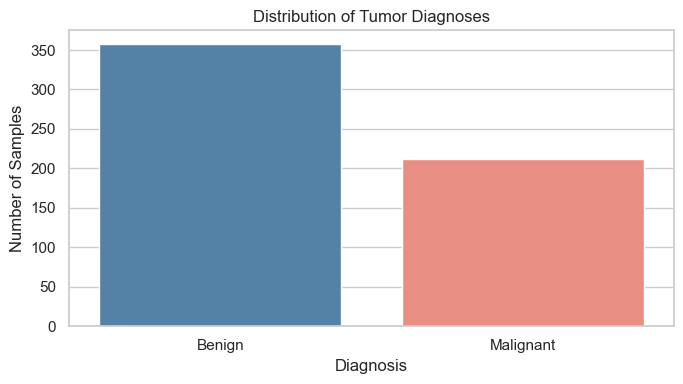

In [39]:

# Display the number of samples in each class
class_counts = df["Diagnosis"].value_counts()

print("Target variable distribution:")
print(class_counts)

# Visualize class distribution
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="Diagnosis",
    order=["Benign", "Malignant"],
    hue="Diagnosis",
    hue_order=["Benign", "Malignant"],
    palette={
        "Benign": "steelblue",
        "Malignant": "salmon"
    },
    legend=False
)

plt.title("Distribution of Tumor Diagnoses")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


- The dataset contains more benign tumors (357) than malignant tumors (212). This class difference should be considered when evaluating the models.

---

In [13]:
print("\nDataset information:")
X.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoo

- This shows the structure of the feature matrix (number of samples, number of features, and data types) for the breast cancer dataset.
- It helps confirm that all columns are numeric and there are no missing values before modeling.

In [14]:
X.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


- This summary shows basic statistics for each feature in the breast cancer dataset, including mean, standard deviation, and value ranges. 
- Most features (such as mean radius, mean perimeter, and mean area) have wide ranges, indicating significant variation in tumor size. 
- We will normalize these features before model training.


---


## 6. Data Cleaning

In [15]:
# Check for missing values
print(X.isnull().sum())

# Check for duplicates
print(f"Duplicate rows: {X.duplicated().sum()}")

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64
Duplicate rows: 0


- No missing values or duplicate rows were found.
- All 30 input features are numeric, so no additional data cleaning was needed for this analysis.

---




## 7. Feature Analysis and Visualizations

### 7.1 Correlation Matrix

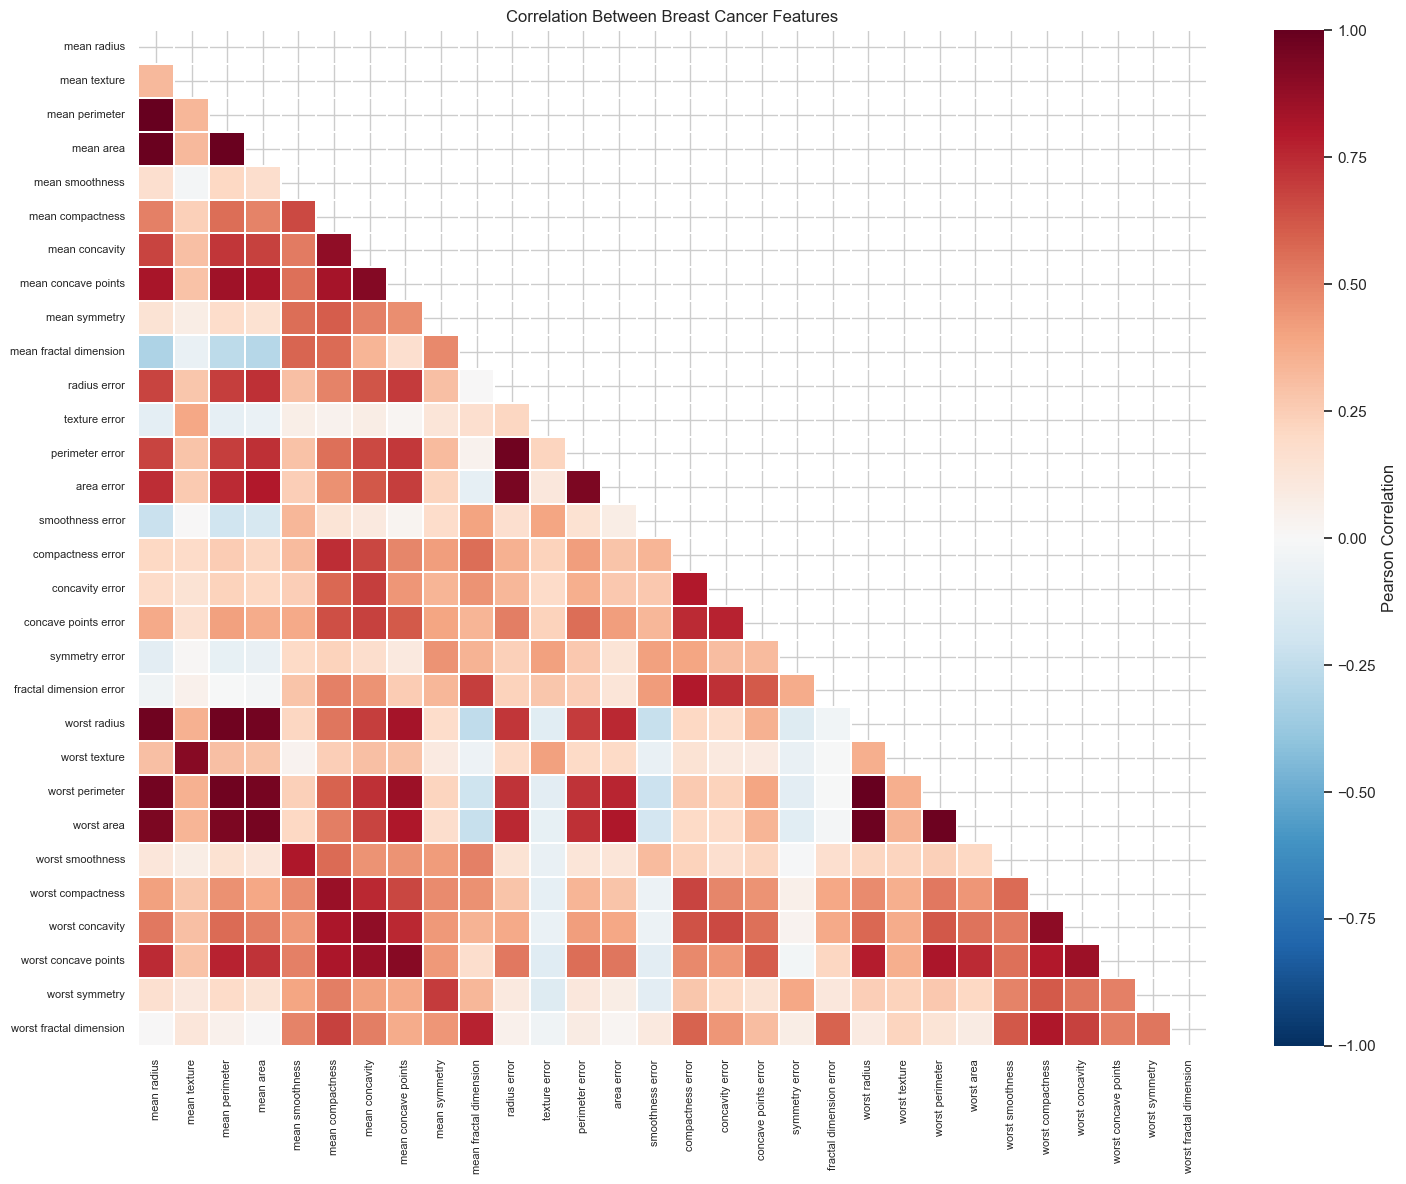

In [40]:
# Calculate correlations between the 30 features
correlation_matrix = X.corr()

# Hide the upper triangle to reduce clutter
mask = np.triu(
    np.ones_like(correlation_matrix, dtype=bool)
)

plt.figure(figsize=(15, 12))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    annot=False,
    linewidths=0.2,
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title("Correlation Between Breast Cancer Features")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()


### Correlation Heatmap Interpretation

- Several features are strongly correlated, especially measurements related to tumor size, such as radius, perimeter, and area.
- This suggests that some features contain overlapping information, which makes dimensionality reduction with PCA worth exploring.
---

### 7.2 KDE Plots (Distributions for Malignant vs Benign)

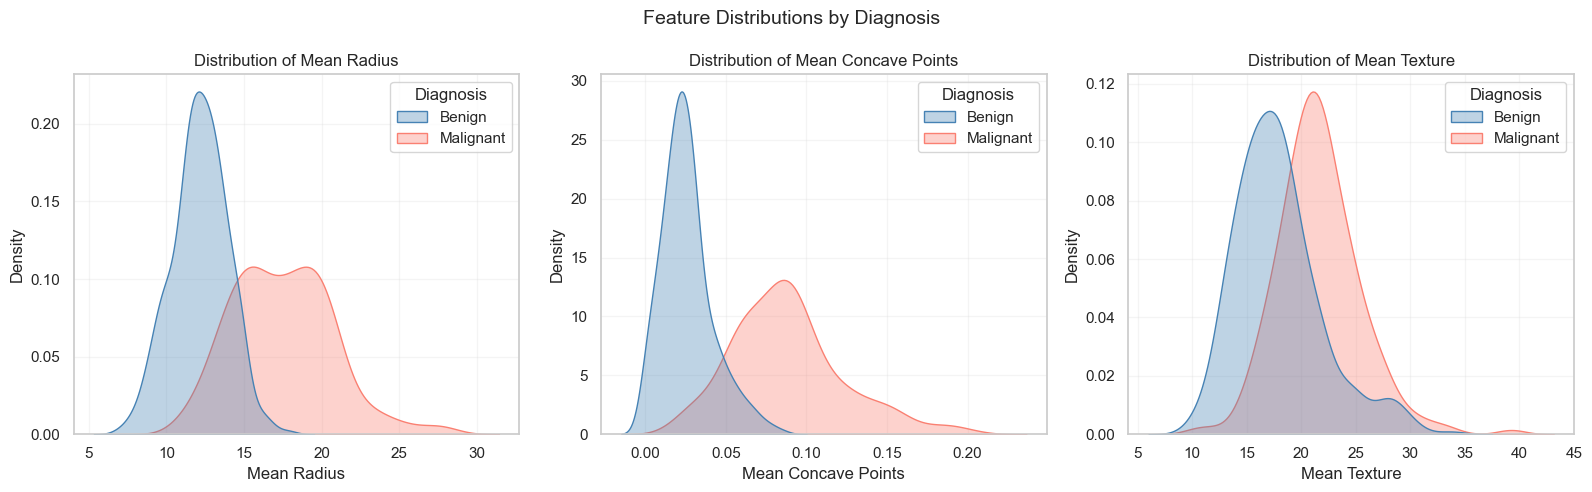

In [41]:

# Compare distributions of three different tumor features
features_to_plot = [
    "mean radius",
    "mean concave points",
    "mean texture"
]

# Consistent colors across visualizations
class_colors = {
    "Benign": "steelblue",
    "Malignant": "salmon"
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

for ax, feature in zip(axes, features_to_plot):

    sns.kdeplot(
        data=df,
        x=feature,
        hue="Diagnosis",
        hue_order=["Benign", "Malignant"],
        palette=class_colors,
        fill=True,
        alpha=0.35,
        common_norm=False,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature.title()}")
    ax.set_xlabel(feature.title())
    ax.set_ylabel("Density")
    ax.grid(alpha=0.2)

plt.suptitle(
    "Feature Distributions by Diagnosis",
    fontsize=14
)

plt.tight_layout()
plt.show()


### KDE Plot Interpretation

- Malignant tumors generally have higher values for mean radius and mean concave points.
- Mean texture also differs between the groups, but the distributions overlap more.
- These plots suggest that size and shape measurements may help distinguish the two classes.

---

### 7.3 Visualizing Class Differences with Scatter Plots

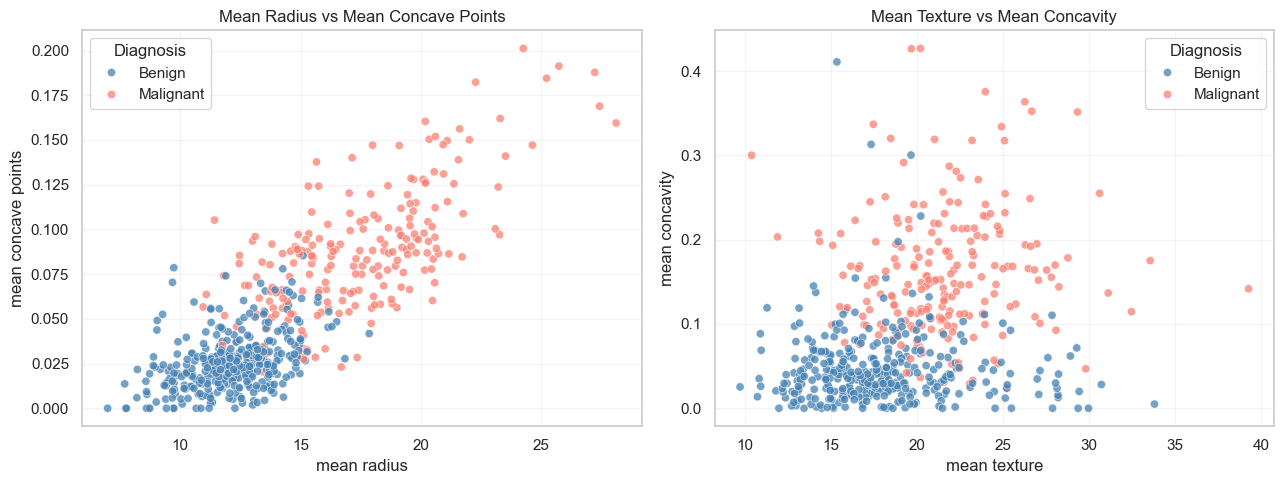

In [42]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Tumor size and shape
sns.scatterplot(
    data=df,
    x="mean radius",
    y="mean concave points",
    hue="Diagnosis",
    hue_order=["Benign", "Malignant"],
    palette=class_colors,
    alpha=0.75,
    ax=axes[0]
)

axes[0].set_title("Mean Radius vs Mean Concave Points")
axes[0].grid(alpha=0.2)

# Plot 2: Texture and shape
sns.scatterplot(
    data=df,
    x="mean texture",
    y="mean concavity",
    hue="Diagnosis",
    hue_order=["Benign", "Malignant"],
    palette=class_colors,
    alpha=0.75,
    ax=axes[1]
)

axes[1].set_title("Mean Texture vs Mean Concavity")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()


### Scatter Plot Interpretation

- Malignant tumors tend to have higher values for radius and concave points, although the classes overlap.
- The second plot also shows some separation based on texture and concavity, but neither pair of features can perfectly distinguish the two classes.

---

### 7.4 Box Plots for Outliers

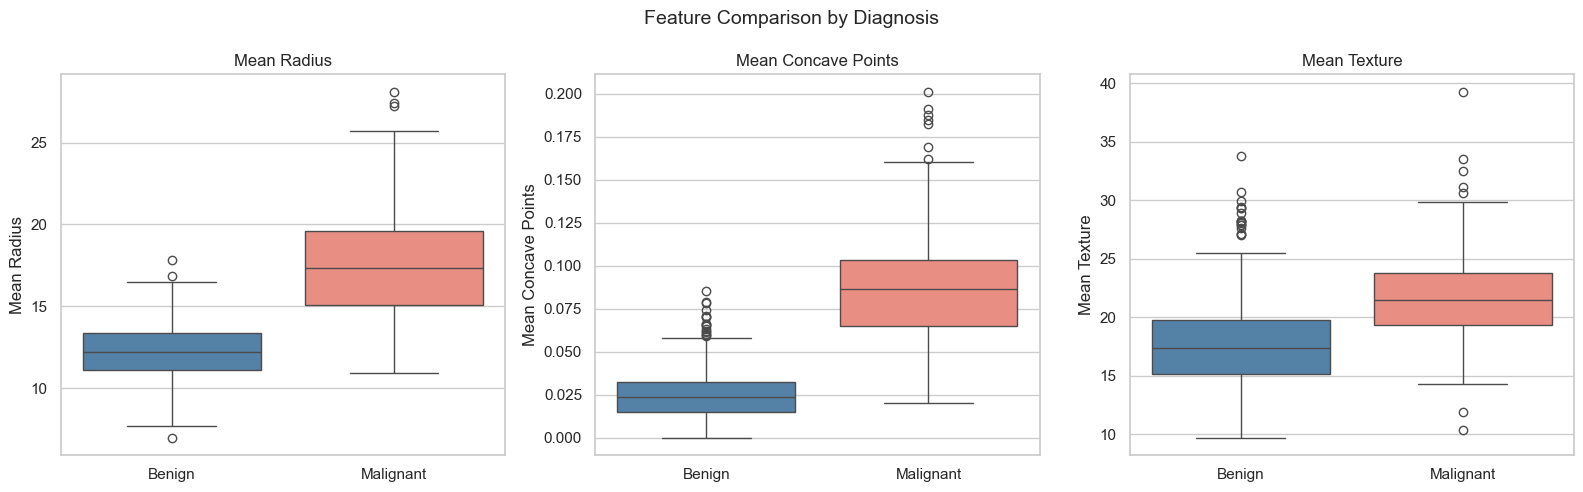

In [43]:

features_to_compare = [
    "mean radius",
    "mean concave points",
    "mean texture"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, feature in zip(axes, features_to_compare):

    sns.boxplot(
        data=df,
        x="Diagnosis",
        y=feature,
        order=["Benign", "Malignant"],
        hue="Diagnosis",
        hue_order=["Benign", "Malignant"],
        palette=class_colors,
        legend=False,
        ax=ax
    )

    ax.set_title(feature.title())
    ax.set_xlabel("")
    ax.set_ylabel(feature.title())

plt.suptitle(
    "Feature Comparison by Diagnosis",
    fontsize=14
)

plt.tight_layout()
plt.show()


### Box Plot Interpretation

- Malignant tumors generally show higher median values for radius and concave points.
- Texture also differs between the groups, but the values overlap more.
- The box plots help compare the spread and median of each feature across the two diagnosis groups.

---


## 8. Split the data
### Split the data into training and test sets

In [45]:
# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.map({0: "Benign", 1: "Malignant"}).value_counts())

print("\nTest class distribution:")
print(y_test.map({0: "Benign", 1: "Malignant"}).value_counts())


Training set: (455, 30)
Test set: (114, 30)

Training class distribution:
target
Benign       285
Malignant    170
Name: count, dtype: int64

Test class distribution:
target
Benign       72
Malignant    42
Name: count, dtype: int64


### Train/Test Split

- I split the dataset into 80% training data and 20% test data.
- Stratification keeps the class proportions similar in both sets. The test data is kept separate from the PCA fitting and model training steps.

---

## 9. Scaling

In [46]:
# Fit the scaler using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the fitted scaler
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)


Scaled training shape: (455, 30)
Scaled test shape: (114, 30)


### Feature Scaling

- I used StandardScaler to put the features on a comparable scale.
- The scaler was fitted only on the training data and then applied to the test data. This prevents information from the test set from influencing preprocessing.

---

## 10. Principal Component Analysis (PCA)
### 10.1 PCA Projection

Explained variance by PC1: 0.446
Explained variance by PC2: 0.185
Total explained variance: 0.631


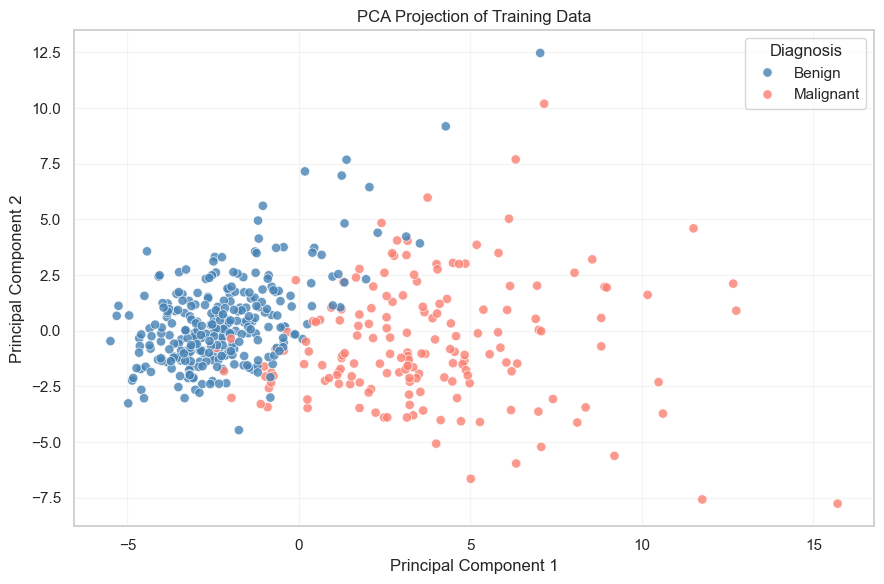

In [47]:

# Reduce the scaled training data to two components
pca_2d = PCA(n_components=2)

X_train_pca = pca_2d.fit_transform(X_train_scaled)

# Transform the test data with the same PCA
X_test_pca = pca_2d.transform(X_test_scaled)

print(
    "Explained variance by PC1:",
    round(pca_2d.explained_variance_ratio_[0], 3)
)

print(
    "Explained variance by PC2:",
    round(pca_2d.explained_variance_ratio_[1], 3)
)

print(
    "Total explained variance:",
    round(pca_2d.explained_variance_ratio_.sum(), 3)
)

# Create a DataFrame for plotting
pca_plot_df = pd.DataFrame({
    "PC1": X_train_pca[:, 0],
    "PC2": X_train_pca[:, 1],
    "Diagnosis": y_train.map({
        0: "Benign",
        1: "Malignant"
    }).to_numpy()
})

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_plot_df,
    x="PC1",
    y="PC2",
    hue="Diagnosis",
    hue_order=["Benign", "Malignant"],
    palette={
        "Benign": "steelblue",
        "Malignant": "salmon"
    },
    alpha=0.8,
    s=45
)

plt.title("PCA Projection of Training Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Diagnosis")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### PCA Projection Interpretation

- The first two principal components explain approximately 63% of the variation in the training data.
- The plot shows some separation between benign and malignant tumors, although the groups overlap.
- This suggests that PCA captures useful patterns, but two components do not fully separate the classes.

### 10.2  Explained Variance Analysis 

Components for 90% variance: 7
Components for 95% variance: 10


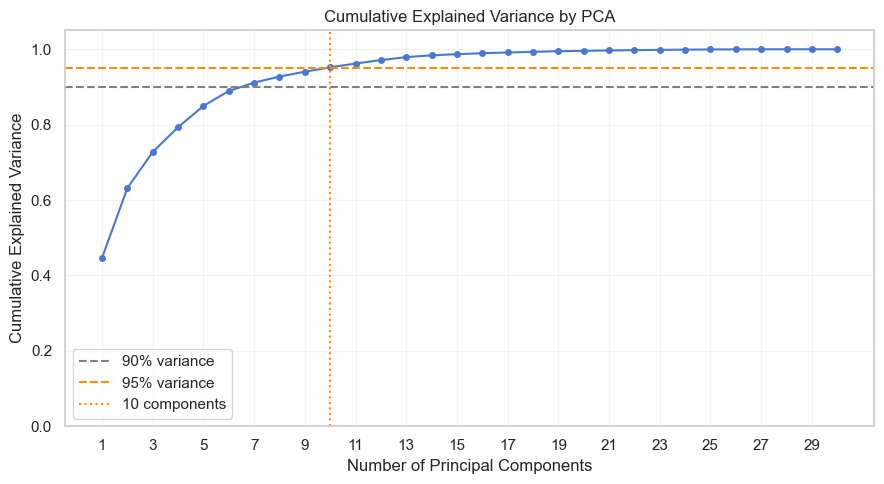

In [48]:
# Fit PCA with all components on scaled training data
pca_full = PCA()
pca_full.fit(X_train_scaled)

# Cumulative explained variance
cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

component_numbers = np.arange(
    1,
    len(cumulative_variance) + 1
)

# Number of components for 90% and 95% variance
n_components_90 = np.searchsorted(
    cumulative_variance, 0.90
) + 1

n_components_95 = np.searchsorted(
    cumulative_variance, 0.95
) + 1

print("Components for 90% variance:", n_components_90)
print("Components for 95% variance:", n_components_95)

# Plot cumulative explained variance
plt.figure(figsize=(9, 5))

plt.plot(
    component_numbers,
    cumulative_variance,
    marker="o",
    markersize=4
)

plt.axhline(
    y=0.90,
    color="gray",
    linestyle="--",
    label="90% variance"
)

plt.axhline(
    y=0.95,
    color="darkorange",
    linestyle="--",
    label="95% variance"
)

plt.axvline(
    x=n_components_95,
    color="darkorange",
    linestyle=":",
    label=f"{n_components_95} components"
)

plt.title("Cumulative Explained Variance by PCA")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.xticks(range(1, 31, 2))
plt.ylim(0, 1.05)
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()


### Explained Variance Results

- PCA reduced the number of dimensions from 30 to 10 while retaining at least 95% of the variance in the training data.
- This suggests that several features contain overlapping information.
- The next step is to check whether models trained with fewer components can achieve similar classification performance.

---

# 11. Model Training and Cross-Validation

- I compared four classification models using the original 30 features and PCA-reduced features.
- For the PCA versions, the number of components was selected to retain at least 95% of the variance.
- I used stratified five-fold cross-validation on the training data. Scaling and PCA were included inside the pipelines to avoid data leakage between folds.
- The main focus is on recall for malignant tumors, along with precision, F1-score, accuracy, and ROC-AUC.

## 11.1  Build the Model Pipelines

In [50]:
# Define the four classifiers
classifiers = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    "SVM": SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    )
}

# Build a pipeline with or without PCA
def build_model_pipeline(model_name, use_pca=False):

    steps = []

    # Scaling is needed for LR, SVM, KNN, and PCA
    if model_name != "Random Forest" or use_pca:
        steps.append(("scaler", StandardScaler()))

    if use_pca:
        steps.append(("pca", PCA(n_components=0.95)))

    steps.append(
        ("classifier", clone(classifiers[model_name]))
    )

    return Pipeline(steps)


# Create two versions of each model
model_pipelines = {}

for model_name in classifiers:

    model_pipelines[(model_name, "Original")] = (
        build_model_pipeline(model_name)
    )

    model_pipelines[(model_name, "PCA")] = (
        build_model_pipeline(model_name, use_pca=True)
    )

print("Number of pipelines:", len(model_pipelines))

for model_name, version in model_pipelines:
    print(f"{model_name} - {version}")

Number of pipelines: 8
Logistic Regression - Original
Logistic Regression - PCA
SVM - Original
SVM - PCA
KNN - Original
KNN - PCA
Random Forest - Original
Random Forest - PCA


## 11.2  Stratified Cross-Validation

In [51]:
# Use the same folds for all eight pipelines
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Focus on malignant tumors as the positive class (1)
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc"
}

cv_results = []

for (model_name, version), pipeline in model_pipelines.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    result = {
        "Model": model_name,
        "Features": version
    }

    for metric in scoring:
        result[metric] = scores[
            f"test_{metric}"
        ].mean()

        result[f"{metric}_Std"] = scores[
            f"test_{metric}"
        ].std()

    cv_results.append(result)

cv_summary = pd.DataFrame(cv_results)

print("Cross-validation results:")
display(
    cv_summary[
        [
            "Model",
            "Features",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC"
        ]
    ].round(3)
)


Cross-validation results:


,Model,Features,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,Original,0.974,0.977,0.953,0.964,0.996
1,Logistic Regression,PCA,0.976,0.982,0.953,0.967,0.994
2,SVM,Original,0.971,0.977,0.947,0.961,0.995
3,SVM,PCA,0.971,0.977,0.947,0.961,0.995
4,KNN,Original,0.965,0.988,0.918,0.951,0.987
5,KNN,PCA,0.967,0.982,0.929,0.954,0.987
6,Random Forest,Original,0.963,0.964,0.935,0.949,0.989
7,Random Forest,PCA,0.958,0.958,0.929,0.943,0.988


## 11.3 Does PCA Help ?

### PCA Comparison

- I compared each model using the original features and PCA-transformed features.

- The comparison focuses on whether reducing the number of dimensions changes recall for malignant tumors and overall class discrimination.

- PCA may simplify the feature representation, but its effect on classification performance needs to be evaluated rather than assumed.

In [52]:
# Separate original-feature and PCA results
original_results = (
    cv_summary[cv_summary["Features"] == "Original"]
    .set_index("Model")
)

pca_results = (
    cv_summary[cv_summary["Features"] == "PCA"]
    .set_index("Model")
)

# Compare performance before and after PCA
pca_comparison = pd.DataFrame({
    "Original Recall": original_results["Recall"],
    "PCA Recall": pca_results["Recall"],
    "Recall Change": (
        pca_results["Recall"] - original_results["Recall"]
    ),
    "Original ROC-AUC": original_results["ROC_AUC"],
    "PCA ROC-AUC": pca_results["ROC_AUC"],
    "ROC-AUC Change": (
        pca_results["ROC_AUC"] - original_results["ROC_AUC"]
    )
})

display(pca_comparison.round(3))


,Original Recall,PCA Recall,Recall Change,Original ROC-AUC,PCA ROC-AUC,ROC-AUC Change
Model,,,,,,
Logistic Regression,0.953,0.953,0.000,0.996,0.994,-0.001
SVM,0.947,0.947,0.000,0.995,0.995,-0.000
KNN,0.918,0.929,0.012,0.987,0.987,0.000
Random Forest,0.935,0.929,-0.006,0.989,0.988,-0.001


### PCA Comparison Results

- PCA reduced the feature representation from 30 dimensions to about 10 while retaining at least 95% of the training-data variance.

- The models performed similarly with and without PCA. Logistic Regression maintained a recall of 0.953, while KNN showed a small increase in recall from 0.918 to 0.929.

- Logistic Regression also achieved the highest ROC-AUC among the original-feature models (0.996).

- These results suggest that PCA can reduce dimensionality without a substantial loss in classification performance on this dataset. However, the small differences between models should not be treated as conclusive.

---

# 12. Final Model Evaluation

- Based on the cross-validation results, I selected Logistic Regression for the final comparison.

- I evaluate two versions: one using the original 30 features and another using PCA to retain at least 95% of the variance.

- The models are fitted on the training data and evaluated on the held-out test set. The focus is on recall for malignant tumors and the effect of dimensionality reduction.

## 12.1 Evaluate Logistic Regression on the Test Set

In [ ]:
# Selected models from cross-validation
selected_models = {
    "Logistic Regression - Original": (
        model_pipelines[("Logistic Regression", "Original")]
    ),
    "Logistic Regression - PCA": (
        model_pipelines[("Logistic Regression", "PCA")]
    )
}

test_results = []
test_predictions = {}
test_probabilities = {}

for name, pipeline in selected_models.items():

    # Train the full pipeline on training data
    pipeline.fit(X_train, y_train)

    # Predict malignant (1) or benign (0)
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    test_predictions[name] = y_pred
    test_probabilities[name] = y_prob

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

test_comparison = pd.DataFrame(test_results)

display(test_comparison.round(3))


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression - Original,0.965,0.975,0.929,0.951,0.996
1,Logistic Regression - PCA,0.974,1.000,0.929,0.963,0.997


## 12.2 Confusion Matrix

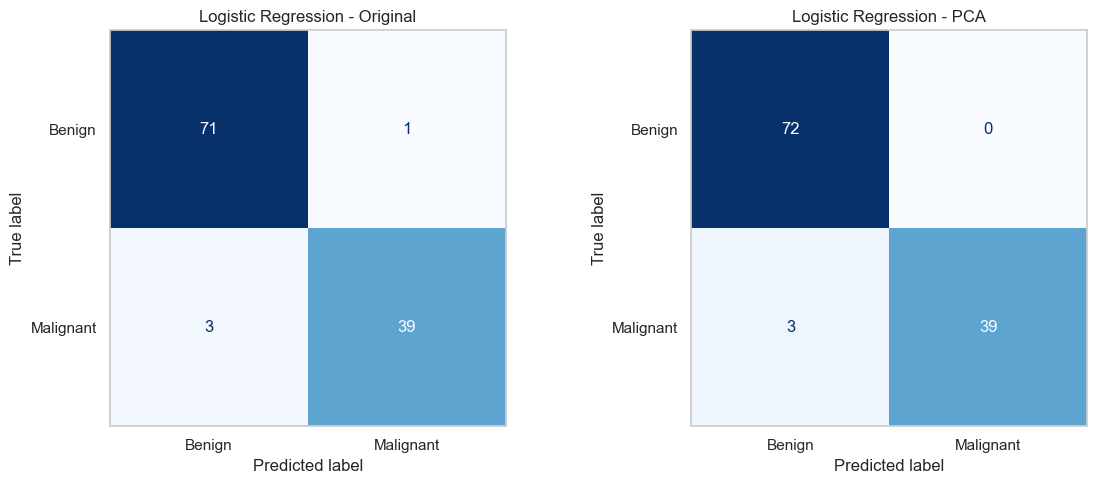

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, predictions) in zip(
    axes,
    test_predictions.items()
):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=["Benign", "Malignant"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(name)
    ax.grid(False)

plt.tight_layout()
plt.show()


## 12.3 ROC Curve Comparison

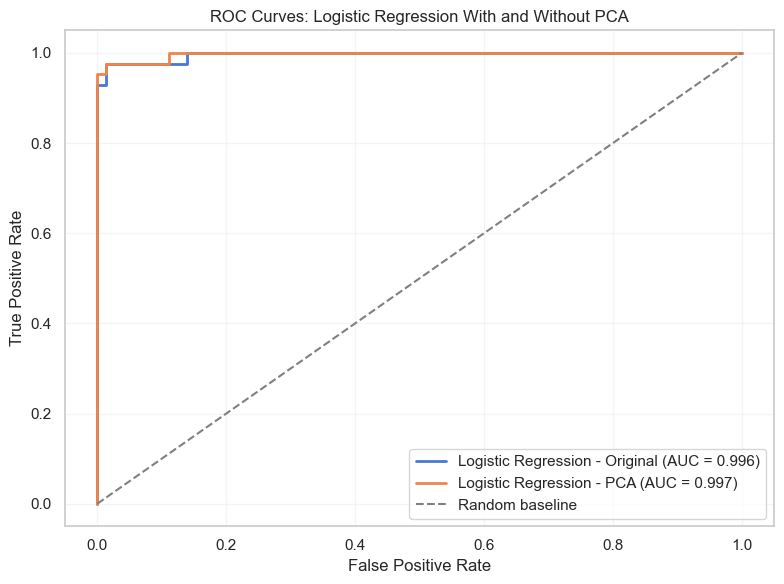

In [60]:
plt.figure(figsize=(8, 6))

for name, probabilities in test_probabilities.items():

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities,
        pos_label=1
    )

    auc = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random baseline"
)

plt.title("ROC Curves: Logistic Regression With and Without PCA")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### Test Set Results

- Both Logistic Regression models performed well on the test set.

- The PCA version achieved slightly higher accuracy (0.974 vs. 0.965), while both models had the same recall for malignant tumors (0.929).

- Each model correctly identified 39 of the 42 malignant tumors and missed 3 cases. The PCA version made no false positive predictions, compared with one for the original model.

- ROC-AUC was also very similar: 0.996 for the original model and 0.997 with PCA.

- Overall, PCA reduced the number of dimensions while maintaining similar classification performance. However, the differences are small, and these results do not establish that PCA is consistently better.

---

## 13. Model Interpretability with SHAP

### 13.1 Introduction
- SHAP helps explain how individual features contribute to a model's predictions.
- In this section, SHAP is used to examine Logistic Regression trained on the original features. This makes it easier to relate the model's predictions to the measured characteristics of breast tumors.
- The analysis uses the training set to fit the model and define the background data. The test set is used to examine the resulting explanations.
- SHAP explains model behavior, not causal relationships or clinical diagnoses.

### 13.2 Prepare the Logistic Regression Pipeline

In [61]:
# Fit Logistic Regression using the original features
shap_lr_pipeline = build_model_pipeline(
    "Logistic Regression",
    use_pca=False
)

shap_lr_pipeline.fit(X_train, y_train)

# Separate preprocessing from the trained classifier
shap_preprocessor = shap_lr_pipeline[:-1]
shap_lr_model = shap_lr_pipeline[-1]

# Transform data using preprocessing fitted on the training set
X_train_transformed = shap_preprocessor.transform(X_train)
X_test_transformed = shap_preprocessor.transform(X_test)

# Preserve the original feature names
feature_names = X_train.columns.tolist()

X_train_shap = pd.DataFrame(
    X_train_transformed,
    columns=feature_names,
    index=X_train.index
)

X_test_shap = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

# Check the fitted model and transformed data
print("Classifier:", type(shap_lr_model).__name__)
print("Model classes:", shap_lr_model.classes_)
print("Training data shape:", X_train_shap.shape)
print("Test data shape:", X_test_shap.shape)

Classifier: LogisticRegression
Model classes: [0 1]
Training data shape: (455, 30)
Test data shape: (114, 30)


### 13.3 Calculate SHAP Values

In [64]:
# Select background data from the training set only
background = X_train_shap.sample(
    n=min(100, len(X_train_shap)),
    random_state=42
)

# Create the SHAP explainer
explainer = shap.LinearExplainer(
    shap_lr_model,
    background
)

# Explain predictions on the test set
shap_values = explainer(X_test_shap)

print("SHAP values shape:", shap_values.values.shape)

SHAP values shape: (114, 30)


### 13.4 Global Feature Importance

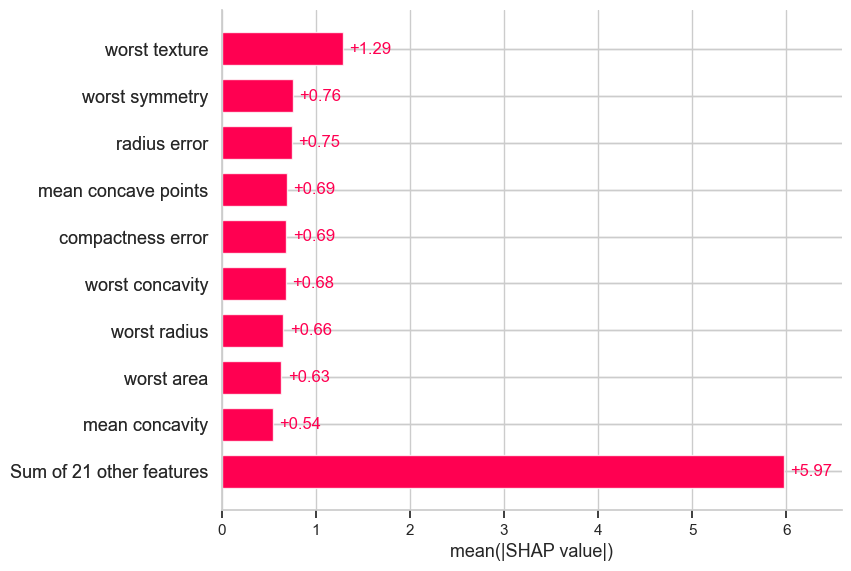

In [65]:
# Global feature importance based on mean absolute SHAP values
shap.plots.bar(
    shap_values,
    max_display=10
)

**Interpretation**

- `worst texture` has the highest average absolute SHAP value among the individual features shown.
- `worst symmetry` and `radius error` are also among the features with larger contributions to the model's predictions.
- The "Sum of 21 other features" bar combines multiple features; it does not represent a single feature.
- This plot shows the overall importance of features, but it does not indicate whether a feature increases or decreases the predicted likelihood of malignancy.

SHAP values explain how the model uses the available features. They do not establish causal relationships or replace clinical judgment.

### 13.5 SHAP Beeswarm Plot

- The beeswarm plot shows how individual feature values contribute to the model's predictions across the test set.
- Each point represents one observation. The horizontal position indicates the SHAP value, while the color represents the feature value, from low (blue) to high (red).
- Positive SHAP values push the model output toward class 1, while negative values push it toward class 0. In this project, these directions correspond to malignant and benign predictions, respectively.

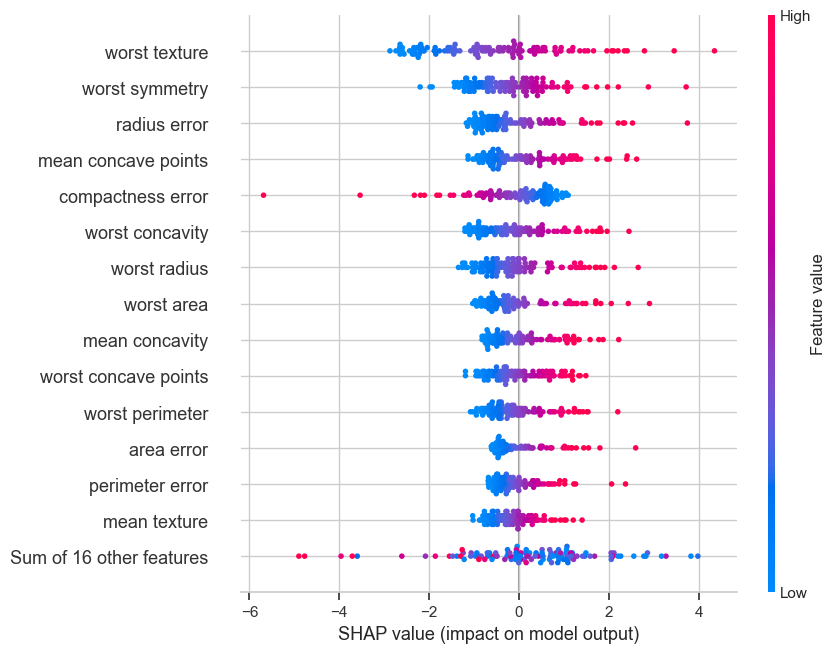

In [66]:
# Visualize feature contributions across the test set
shap.plots.beeswarm(
    shap_values,
    max_display=15
)

**Interpretation**

- `worst texture` has the largest overall contribution among the features shown.
- Higher values of `worst symmetry`, `radius error`, and `mean concave points` generally push predictions toward the malignant class.
- `compactness error` shows a different pattern, with higher values often contributing in the opposite direction.
- Each point represents one test observation. The spread of points shows how a feature's contribution varies across observations.

These patterns describe how the Logistic Regression model makes predictions. They do not establish that a feature causes cancer, and correlated features can affect how individual contributions are distributed.

### 13.6 Explaining an Individual Prediction with SHAP Waterfall

- The waterfall plot explains how individual features contribute to a single prediction.

- Starting from the model's baseline output, each feature shifts the prediction toward either the benign or malignant class. The plot helps illustrate how several feature contributions combine to produce the final model output.
- This example explains one model prediction and should not be interpreted as a clinical diagnosis.

Test observation index: 503
Actual class: 1
Predicted class: 1
Predicted probability of malignancy: 1.0


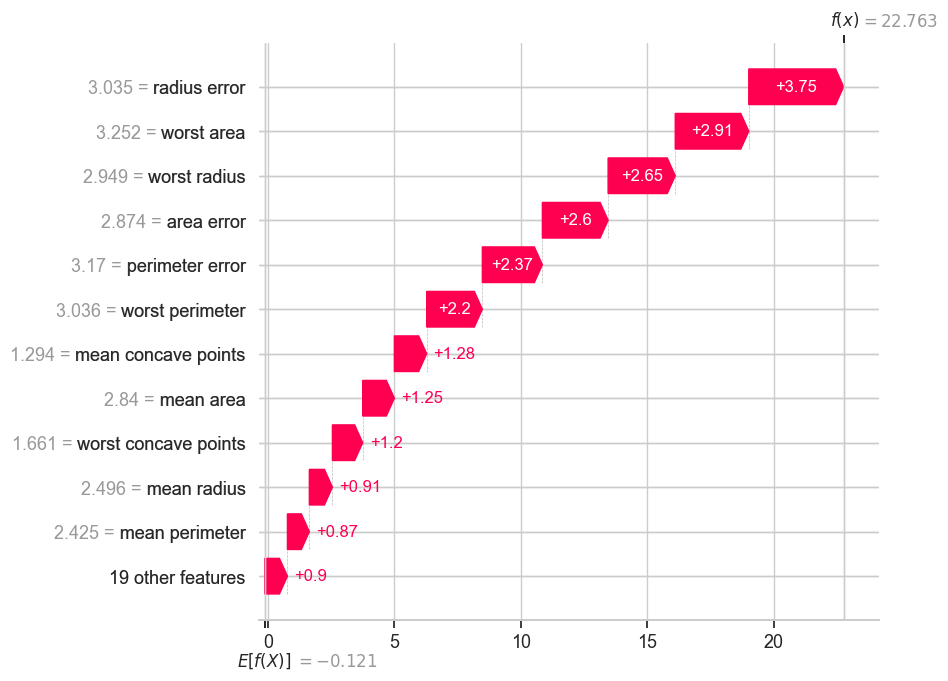

In [68]:
# Get predicted probabilities using the full pipeline
test_probabilities = shap_lr_pipeline.predict_proba(
    X_test
)[:, 1]

# Select the test observation with the highest
# predicted probability of malignancy
sample_idx = np.argmax(test_probabilities)

# Get the actual and predicted classes
actual_class = y_test.iloc[sample_idx]

predicted_class = shap_lr_pipeline.predict(
    X_test.iloc[[sample_idx]]
)[0]

# Display prediction details
print(
    "Test observation index:",
    X_test.index[sample_idx]
)
print("Actual class:", actual_class)
print("Predicted class:", predicted_class)
print(
    "Predicted probability of malignancy:",
    round(test_probabilities[sample_idx], 3)
)

# Explain the individual prediction
shap.plots.waterfall(
    shap_values[sample_idx],
    max_display=12
)

**Interpretation**

- The selected test observation belongs to the malignant class, and the model correctly predicted it as malignant.
- `radius error` made the largest individual contribution to this prediction, followed by `worst area`, `worst radius`, and `area error`.
- The positive SHAP contributions pushed the model output toward the malignant class.
- The model's output was 22.763, corresponding to a predicted probability that rounds to 1.000.

This example illustrates how multiple features contribute to one prediction. The selected observation has the highest predicted malignancy probability in the test set, so it should not be considered representative of all cases.

SHAP explains the model's behavior, not the causes of cancer. The feature values shown in the plot are standardized values, not the original clinical measurements.

### 13.7 SHAP Analysis Summary

SHAP was used to examine the Logistic Regression model at both the global and individual levels.

The global analysis highlighted `worst texture`, `worst symmetry`, and `radius error` among the most influential features. The beeswarm plot showed how feature contributions varied across test observations, while the waterfall plot illustrated the contributions for one individual prediction.

These explanations help describe how the model uses the available features. They do not establish causal relationships or demonstrate that the model is suitable for clinical use.

---